In [1]:
!pip install pennylane -q

In [2]:
import numpy as onp
import pennylane as qml
from pennylane import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC

# ---- Data: Iris, versicolor vs virginica ----
X, y = load_iris(return_X_y=True)
mask = y != 0
X, y = X[mask], y[mask]
y = onp.where(y == 1, -1, 1)

# Split FIRST, then scale (no leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

scaler = MinMaxScaler((0, onp.pi))
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ---- Quantum model ----
n_qubits, n_layers = 4, 3
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev)
def circuit(weights, x):
    qml.AngleEmbedding(x, wires=range(n_qubits))
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    return qml.expval(qml.PauliZ(0))

def cost(weights, X, y):
    preds = np.stack([circuit(weights, x) for x in X])
    return np.mean((preds - y) ** 2)

def accuracy(weights, X, y):
    preds = onp.sign([float(circuit(weights, x)) for x in X])
    return onp.mean(preds == y)

shape = qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_qubits)
rng = onp.random.default_rng(0)
weights = np.array(rng.uniform(0, 2 * onp.pi, shape), requires_grad=True)

# ---- Training ----
opt = qml.AdamOptimizer(0.1)
losses = []
for epoch in range(40):
    weights, loss = opt.step_and_cost(lambda w: cost(w, X_train, y_train), weights)
    losses.append(float(loss))
    if (epoch + 1) % 5 == 0:
        print(f"epoch {epoch+1:02d}  loss {loss:.4f}")

print("\nQuantum train acc:", accuracy(weights, X_train, y_train))
print("Quantum test acc: ", accuracy(weights, X_test, y_test))

# ---- Classical baseline ----
svm = SVC(kernel="rbf").fit(X_train, y_train)
print("SVM train acc:    ", svm.score(X_train, y_train))
print("SVM test acc:     ", svm.score(X_test, y_test))

epoch 05  loss 0.4582
epoch 10  loss 0.2956
epoch 15  loss 0.2238
epoch 20  loss 0.2016
epoch 25  loss 0.2021
epoch 30  loss 0.1925
epoch 35  loss 0.1881
epoch 40  loss 0.1866

Quantum train acc: 0.9714285714285714
Quantum test acc:  0.8666666666666667
SVM train acc:     0.9571428571428572
SVM test acc:      0.8666666666666667


layers=1  test acc = 0.880 ± 0.065   (train 0.837)
layers=2  test acc = 0.940 ± 0.013   (train 0.926)
layers=3  test acc = 0.967 ± 0.021   (train 0.940)
layers=4  test acc = 0.967 ± 0.021   (train 0.946)
SVM         test acc = 0.980 ± 0.016


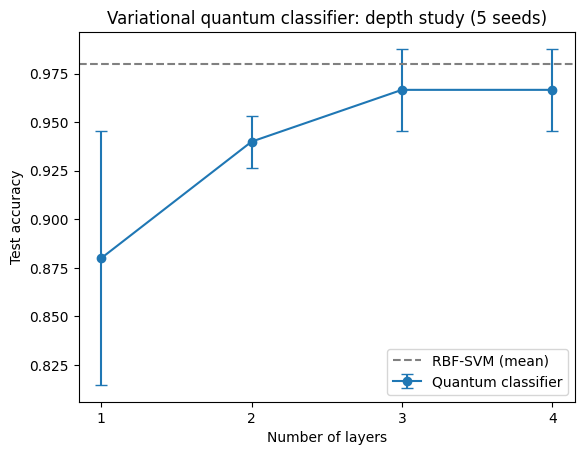

In [3]:
import matplotlib.pyplot as plt

def get_split(seed):
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.3, random_state=seed, stratify=y)
    sc = MinMaxScaler((0, onp.pi))
    return sc.fit_transform(Xtr), sc.transform(Xte), ytr, yte

def train_qvc(n_layers, seed, epochs=40):
    Xtr, Xte, ytr, yte = get_split(seed)
    shape = qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_qubits)
    rng = onp.random.default_rng(seed)
    w = np.array(rng.uniform(0, 2 * onp.pi, shape), requires_grad=True)

    def batch_cost(w):
        preds = circuit(w, Xtr)          # batched over all samples at once
        return np.mean((preds - ytr) ** 2)

    opt = qml.AdamOptimizer(0.1)
    for _ in range(epochs):
        w = opt.step(batch_cost, w)

    test_pred = onp.sign(onp.array(circuit(w, Xte)))
    train_pred = onp.sign(onp.array(circuit(w, Xtr)))
    return onp.mean(train_pred == ytr), onp.mean(test_pred == yte)

seeds = [0, 1, 2, 3, 4]
depths = [1, 2, 3, 4]
results = {d: [] for d in depths}
train_results = {d: [] for d in depths}
svm_test = []

for s in seeds:
    Xtr, Xte, ytr, yte = get_split(s)
    svm_test.append(SVC(kernel="rbf").fit(Xtr, ytr).score(Xte, yte))

for d in depths:
    for s in seeds:
        tr, te = train_qvc(d, s)
        train_results[d].append(tr)
        results[d].append(te)
    print(f"layers={d}  test acc = {onp.mean(results[d]):.3f} ± {onp.std(results[d]):.3f}"
          f"   (train {onp.mean(train_results[d]):.3f})")

print(f"SVM         test acc = {onp.mean(svm_test):.3f} ± {onp.std(svm_test):.3f}")

# ---- Plot ----
means = [onp.mean(results[d]) for d in depths]
stds = [onp.std(results[d]) for d in depths]
plt.errorbar(depths, means, yerr=stds, marker="o", capsize=4, label="Quantum classifier")
plt.axhline(onp.mean(svm_test), color="gray", linestyle="--", label="RBF-SVM (mean)")
plt.xticks(depths)
plt.xlabel("Number of layers")
plt.ylabel("Test accuracy")
plt.title("Variational quantum classifier: depth study (5 seeds)")
plt.legend()
plt.savefig("depth_study.png", dpi=150, bbox_inches="tight")
plt.show()